1. Data Loading and Exploration:
Utilize Pandas to load the dataset and explore its initial structure.
Summarize features, target variable, and their respective data types.
Conduct basic descriptive statistics for an overview of the dataset.

In [10]:
import pandas as pd

df = pd.read_csv("train1.csv")

print(df.head())

print(df.shape)

print(df.info())

df["price_range"].value_counts().sort_index()

print (df.describe())


   battery_power  blue  clock_speed  dual_sim  fc  four_g  int_memory  m_dep  \
0            842     0          2.2         0   1       0           7    0.6   
1           1021     1          0.5         1   0       1          53    0.7   
2            563     1          0.5         1   2       1          41    0.9   
3            615     1          2.5         0   0       0          10    0.8   
4           1821     1          1.2         0  13       1          44    0.6   

   mobile_wt  n_cores  ...  px_height  px_width   ram  sc_h  sc_w  talk_time  \
0        188        2  ...         20       756  2549     9     7         19   
1        136        3  ...        905      1988  2631    17     3          7   
2        145        5  ...       1263      1716  2603    11     2          9   
3        131        6  ...       1216      1786  2769    16     8         11   
4        141        2  ...       1208      1212  1411     8     2         15   

   three_g  touch_screen  wifi  price_

2. Data Cleaning and Preprocessing:
Address missing or null values.
Transform categorical data into numerical format using suitable methods.


In [28]:
print(df.isnull().sum())

categorical_columns = df.select_dtypes(include=["object"]).columns

print(categorical_columns)


Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64
Index(['Date'], dtype='str')


/var/folders/nh/33ykvngx3jd2q42_ly8d5kx00000gn/T/ipykernel_49922/594292266.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object"]).columns


3. Statistical Analysis with NumPy and SciPy:
Execute detailed statistical analysis on each feature, including:
Calculation of central tendency measures (mean, median, mode).
Analysis of variability (range, variance, standard deviation).
Evaluation of distribution shapes through skewness and kurtosis.
Perform hypothesis testing for statistical significance between groups (e.g., different price ranges).
Investigate feature-target correlations using SciPy.
Apply advanced SciPy statistical functions for deeper insights.

In [32]:
import pandas as pd
import numpy as np
from scipy import stats

# Load the mobile-phone dataset
df = pd.read_csv("train1.csv")

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# The value we want to understand or predict
target = "price_range"

# All columns except price_range are features
features = df.columns.drop(target)

# Convert the feature data into a NumPy array
feature_values = df[features].to_numpy()


# --------------------------------------------------
# 1. Statistical analysis of each feature
# --------------------------------------------------

summary_table = pd.DataFrame({
    "Feature": features,
    "Mean": np.mean(feature_values, axis=0),
    "Median": np.median(feature_values, axis=0),
    "Mode": stats.mode(
        feature_values,
        axis=0,
        keepdims=False
    ).mode,
    "Range": np.ptp(feature_values, axis=0),
    "Variance": np.var(feature_values, axis=0, ddof=1),
    "Standard Deviation": np.std(
        feature_values,
        axis=0,
        ddof=1
    ),
    "Skewness": stats.skew(feature_values, axis=0),
    "Kurtosis": stats.kurtosis(feature_values, axis=0)
})

print("STATISTICAL SUMMARY")
print(summary_table.round(2))


# --------------------------------------------------
# 2. Hypothesis test
# --------------------------------------------------

# RAM values for phones in price ranges 0 and 1
low_price_ram = df[
    df["price_range"].isin([0, 1])
]["ram"]

# RAM values for phones in price ranges 2 and 3
high_price_ram = df[
    df["price_range"].isin([2, 3])
]["ram"]

# Compare the average RAM of the two groups
t_test = stats.ttest_ind(
    low_price_ram,
    high_price_ram,
    equal_var=False
)

print("\nHYPOTHESIS TEST")
print("Average RAM for lower-price phones:", low_price_ram.mean())
print("Average RAM for higher-price phones:", high_price_ram.mean())
print("T-test p-value:", t_test.pvalue)


# --------------------------------------------------
# 3. Feature-target correlations
# --------------------------------------------------

correlation_results = []

for feature in features:
    correlation, p_value = stats.pearsonr(
        df[feature],
        df[target]
    )

    correlation_results.append({
        "Feature": feature,
        "Correlation": correlation,
        "P-value": p_value
    })

correlation_table = pd.DataFrame(correlation_results)

# Sort from strongest positive correlation to weakest
correlation_table = correlation_table.sort_values(
    "Correlation",
    ascending=False
)

print("\nCORRELATIONS WITH PRICE RANGE")
print(correlation_table.round(4))


# --------------------------------------------------
# 4. Advanced SciPy analysis: finding outliers
# --------------------------------------------------

# Calculate the z-score of every feature value
z_scores = np.abs(
    stats.zscore(feature_values, axis=0)
)

# Count values more than three standard deviations away
outlier_counts = np.sum(z_scores > 3, axis=0)

outlier_table = pd.DataFrame({
    "Feature": features,
    "Outlier Count": outlier_counts
})

print("\nOUTLIER COUNTS")
print(outlier_table)

STATISTICAL SUMMARY
          Feature     Mean  Median    Mode   Range    Variance  \
0   battery_power  1238.52  1226.0   618.0  1497.0   193088.36   
1            blue     0.50     0.0     0.0     1.0        0.25   
2     clock_speed     1.52     1.5     0.5     2.5        0.67   
3        dual_sim     0.51     1.0     1.0     1.0        0.25   
4              fc     4.31     3.0     0.0    19.0       18.85   
5          four_g     0.52     1.0     1.0     1.0        0.25   
6      int_memory    32.05    32.0    27.0    62.0      329.27   
7           m_dep     0.50     0.5     0.1     0.9        0.08   
8       mobile_wt   140.25   141.0   182.0   120.0     1253.14   
9         n_cores     4.52     4.0     4.0     7.0        5.23   
10             pc     9.92    10.0    10.0    20.0       36.78   
11      px_height   645.11   564.0   347.0  1960.0   196941.41   
12       px_width  1251.52  1247.0   874.0  1498.0   186796.36   
13            ram  2124.21  2146.5  1229.0  3742.0  1176

4. Data Visualization with Matplotlib:
Produce histograms, scatter plots, and box plots for data distribution and relationship insights.
Employ heatmaps for correlation visualization.
Ensure clarity in plots with appropriate titles, labels, and axis information.

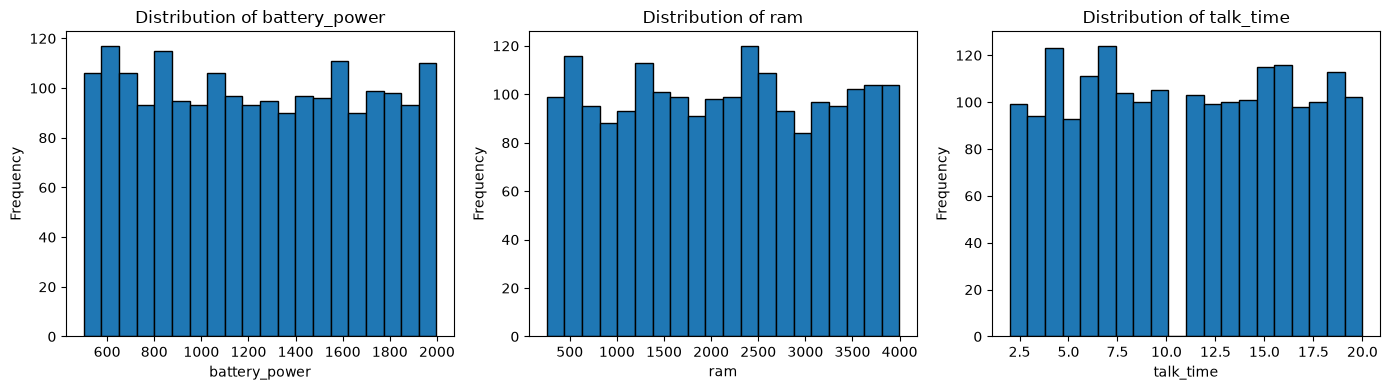

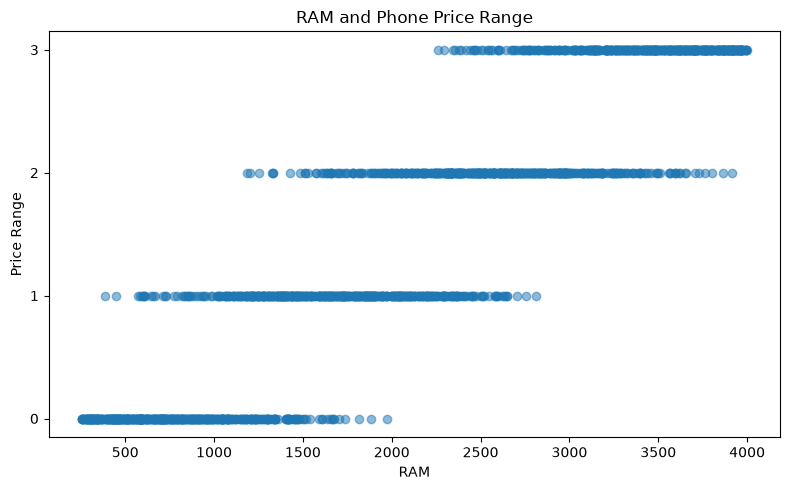

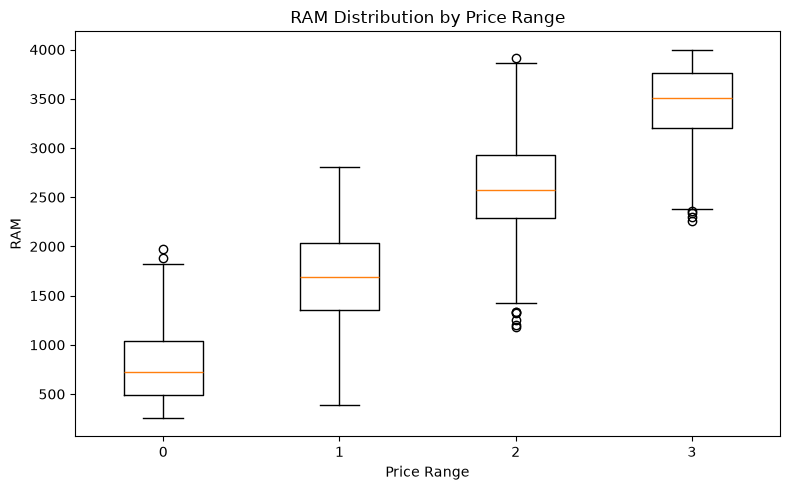

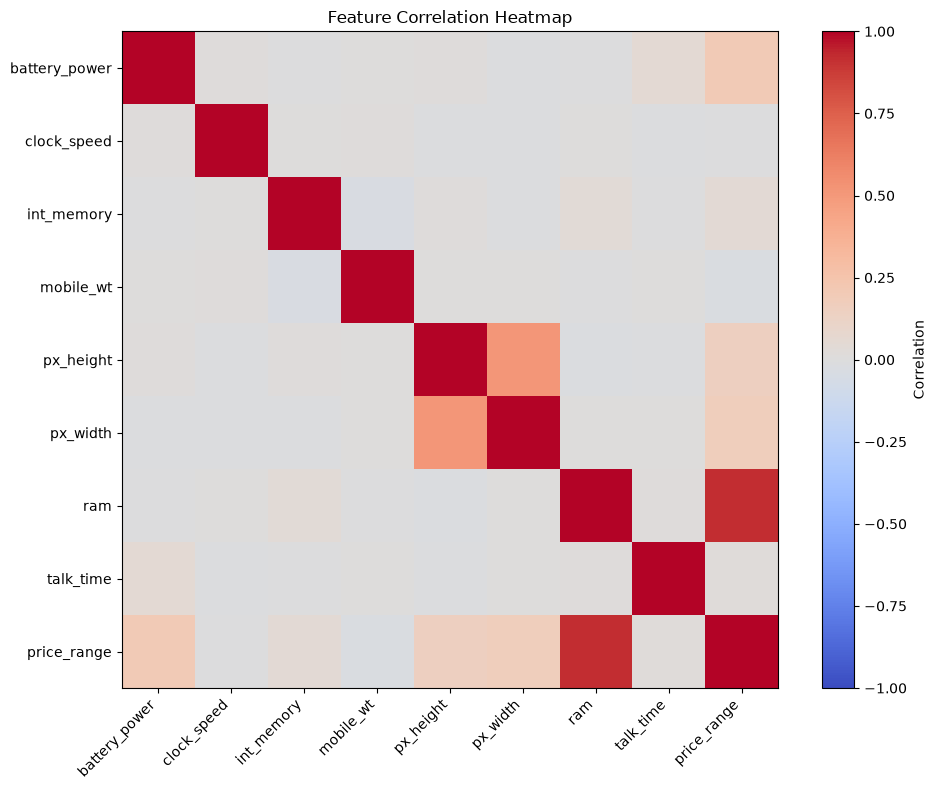

In [33]:
import matplotlib.pyplot as plt


# --------------------------------------------------
# 1. Histograms
# --------------------------------------------------

histogram_features = [
    "battery_power",
    "ram",
    "talk_time"
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for axis, feature in zip(axes, histogram_features):
    axis.hist(
        df[feature],
        bins=20,
        edgecolor="black"
    )

    axis.set_title(f"Distribution of {feature}")
    axis.set_xlabel(feature)
    axis.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. Scatter plot
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    df["ram"],
    df["price_range"],
    alpha=0.5
)

plt.title("RAM and Phone Price Range")
plt.xlabel("RAM")
plt.ylabel("Price Range")
plt.yticks([0, 1, 2, 3])

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. Box plot
# --------------------------------------------------

ram_groups = [
    df[df["price_range"] == 0]["ram"],
    df[df["price_range"] == 1]["ram"],
    df[df["price_range"] == 2]["ram"],
    df[df["price_range"] == 3]["ram"]
]

plt.figure(figsize=(8, 5))

plt.boxplot(ram_groups)

plt.title("RAM Distribution by Price Range")
plt.xlabel("Price Range")
plt.ylabel("RAM")
plt.xticks([1, 2, 3, 4], [0, 1, 2, 3])

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Correlation heatmap
# --------------------------------------------------

heatmap_features = [
    "battery_power",
    "clock_speed",
    "int_memory",
    "mobile_wt",
    "px_height",
    "px_width",
    "ram",
    "talk_time",
    "price_range"
]

correlation_matrix = df[heatmap_features].corr()

fig, axis = plt.subplots(figsize=(10, 8))

heatmap = axis.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

axis.set_title("Feature Correlation Heatmap")

axis.set_xticks(range(len(heatmap_features)))
axis.set_yticks(range(len(heatmap_features)))

axis.set_xticklabels(
    heatmap_features,
    rotation=45,
    ha="right"
)

axis.set_yticklabels(heatmap_features)

plt.colorbar(
    heatmap,
    ax=axis,
    label="Correlation"
)

plt.tight_layout()
plt.show()

5. Insight Synthesis and Conclusion:
Derive conclusions from statistical tests and visualizations.
Identify key determinants in mobile price classification.
Highlight any unexpected or significant findings.


## 5. Insight Synthesis and Conclusion

The statistical analysis shows that **RAM is the strongest determinant of a mobile phone’s price classification**. RAM has a correlation of approximately **0.917** with `price_range`, indicating a very strong positive relationship. As RAM increases, the phone generally moves into a higher price category.

The average RAM increases consistently across the four categories:

- Price range 0: approximately 785 MB
- Price range 1: approximately 1,680 MB
- Price range 2: approximately 2,583 MB
- Price range 3: approximately 3,449 MB

The RAM box plot and scatter plot support this finding. The four price groups have clearly separated RAM distributions, with median RAM increasing from approximately 720 MB in price range 0 to 3,510 MB in price range 3.

The hypothesis test also found a statistically significant difference between the lower-price and higher-price groups. Phones in price ranges 0 and 1 had an average RAM of approximately 1,232 MB, while phones in price ranges 2 and 3 had an average of approximately 3,016 MB. The t-test produced a p-value below 0.05, so the difference is statistically significant.

Other features have weaker positive relationships with price range:

- Battery power: correlation of approximately 0.201
- Pixel width: correlation of approximately 0.166
- Pixel height: correlation of approximately 0.149

These results suggest that battery capacity and screen resolution contribute to price classification, but their relationships are much weaker than RAM.

Most remaining features have correlations close to zero. Features such as Wi-Fi, Bluetooth, 4G, number of processor cores, clock speed, touch screen, and talk time show little direct relationship with price range in this dataset.

One unexpected finding is that technical features commonly associated with premium phones—such as 4G, Wi-Fi, touch-screen support, and processor cores—are not strong determinants of price classification. RAM is much more influential than these features.

The dataset is balanced, containing 500 phones in each price category. This is useful because no single price category dominates the analysis. Most features also contain few extreme outliers, although the front-camera feature contains several unusually high values.

Overall, RAM is the most important feature for distinguishing mobile-phone price categories. Battery power and screen resolution provide some additional information, while most connectivity and design features have relatively weak individual relationships with price range. These findings indicate that RAM should receive particular attention when developing a mobile price-classification model.